In [1]:
from ET_pylib.setup import *
setup_notebook()

# Kernekraftstød: figurer

Figurer for basisforløbet mod kernekraftforløbet i GrønREFORM, hvor ny kernekraft i DK1 og DK2 erstatter havvind. Velfærdsåret er 2040.

*`1. opsætning`*

*vælg geografi, år og kørsel*

In [2]:
# 1. opsætning
GEO   = "disaggEA"
print("Kernekraft-id'er:", ", ".join(f"{i} (fra {y})" for i, y in use_geography(GEO).items()))

yr    = 2040
ids   = NUCLEAR_IDS_BY_GEO[GEO]
RUN   = "disaggEA_2040_kf25om"           # 2040 med brintfiks
SHOCK = "shock_nuc_2040.pkl"
# RUN   = "disaggEA_2025_2050"           # DREAMs 2025-2050 uden brintfiks

Kernekraft-id'er: idNUC_DK1 (fra 2035), idNUC_DK2 (fra 2035)


*`2. data`*

*indlæs basis- og stødforløb og vis kapacitetsbyttet*

In [3]:
# 2. data
baseline_output, shock_output = load_run(RUN, SHOCK)
nuc, cut = nuc_wind_swap(baseline_output, shock_output, yr=yr, nuc_ids=ids)
id2Pt, id2EA = shock_output["id2Pt"].vals, shock_output["id2EA"].vals   # nuclear-ids findes kun i shock-db

c:\Users\LinusLindquist\anaconda3\Lib\site-packages\gams\core\numpy\gams2numpy.py:72: UserWarning: The GAMS version (49.4.0) differs from the API version (54.2.2).
  ws = GamsWorkspace()


Kapacitetsbytte — 2040 (GW)
                    basis  stød      Δ
──────────────────────────────────────
Kernekraft DK1       0,00  0,65  +0,65
Kernekraft DK2       0,00  0,35  +0,35
Havvind DK1          4,50  3,22  -1,28
Havvind DK2          1,79  1,25  -0,55
──────────────────────────────────────
Kernekraft i alt                 +1,00
Havvind i alt                    -1,82
──────────────────────────────────────
Havvind fjernet pr. GW kernekraft: 1,82



*byg timebalancerne og forsyningsandelene til attribuering af nettoeksport*

In [4]:
ctx_el     = build_el_balance_data(baseline_output, shock_output, years=yr)
ctx_el_agg = build_el_balance_data_country(baseline_output, shock_output, years=yr)
shares     = build_supply_shares(ctx_el, aggregates=c_aggs_countries)

*`3. timebalance`*

*elbalance, nettoeksport og nettoeksport pr. anlægstype for Danmark, timer sorteret efter pris*

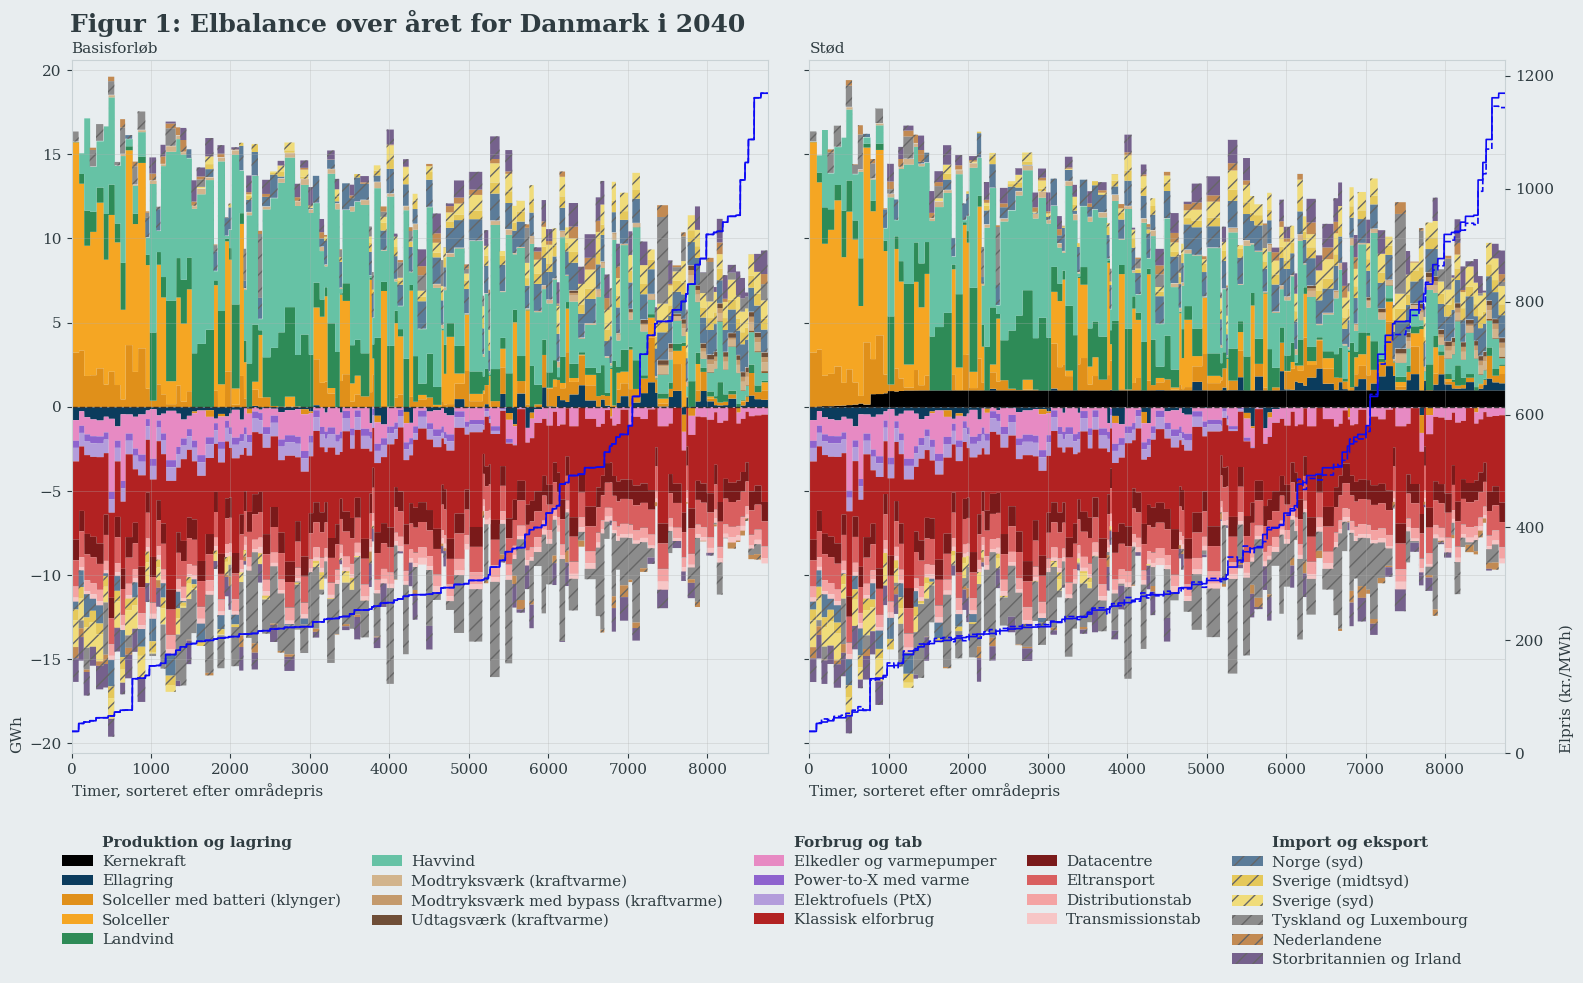

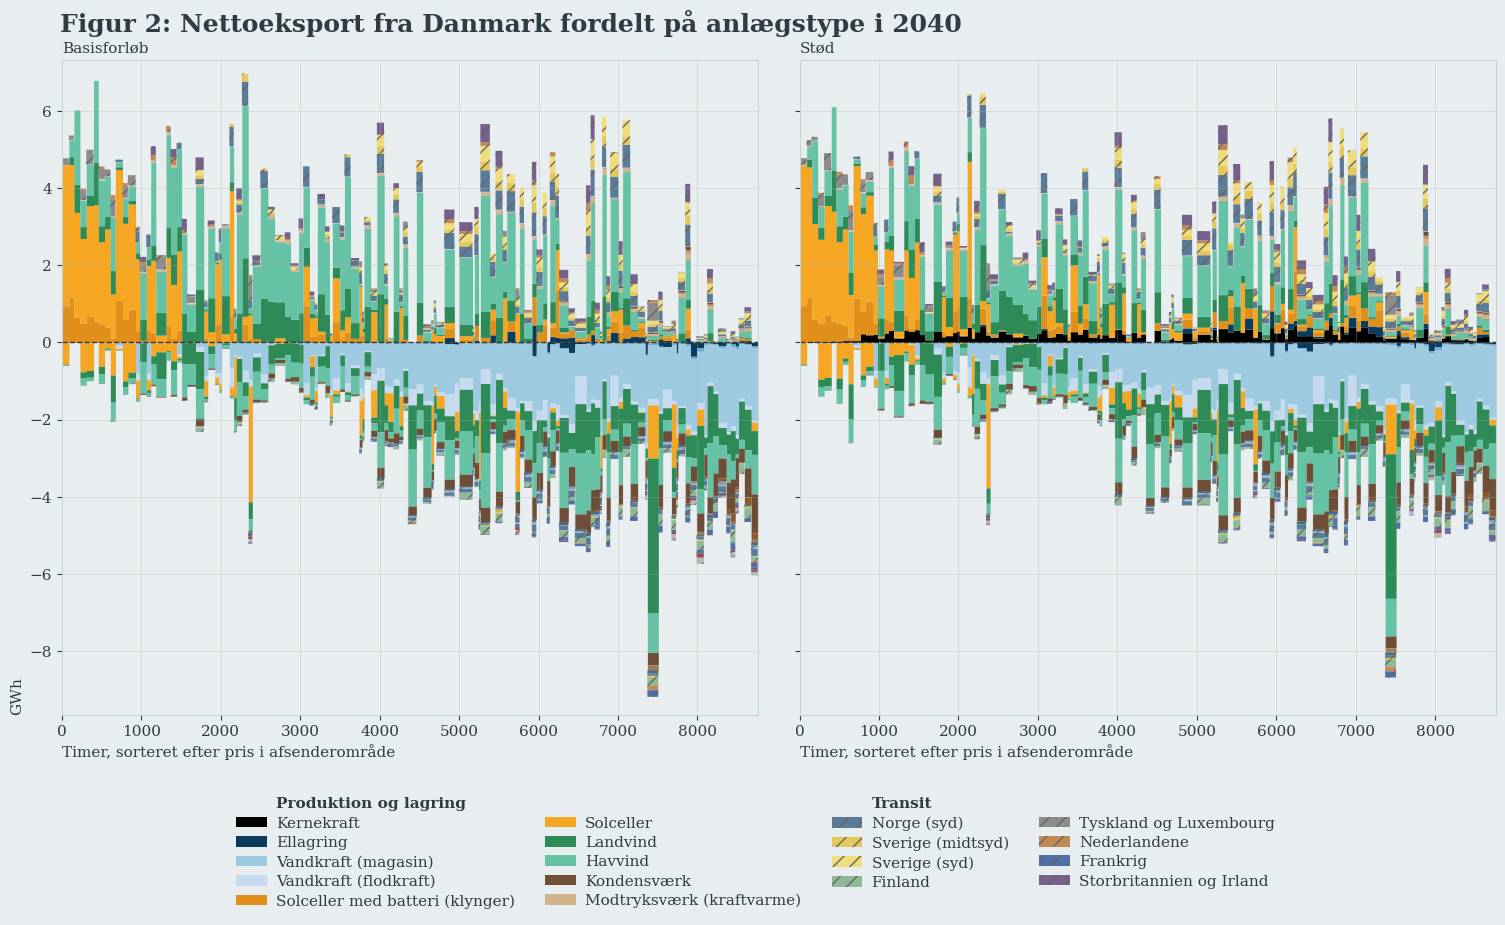

In [22]:
# 3. timebalance
plot_energy_balance_el(ctx_el_agg, "DK", years=yr, figsize=(18.5, 9),
                       legend_min_twh=0.2)
# plot_net_export(ctx_el_agg, "DK", years=yr)
plot_net_export_by_pt_agg(
    ctx_el_agg, "DK", ["SE", "NO", "DELU", "GBNIIE", "NL"],
    share_dict=shares, partner_map=c_aggs_countries, years=yr, legend_min_twh=0.2,
    figsize=(18.5, 8.5),
);

*`4. priser`*

*prisændring pr. time mod basisprisen og ΔCS i de samme prisbins*

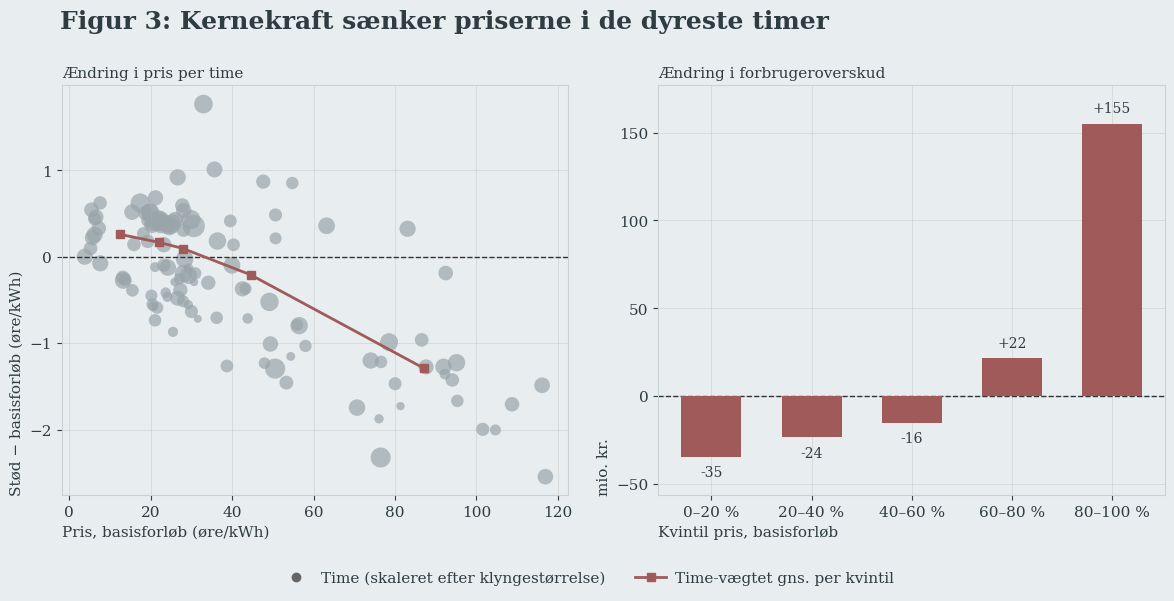

In [6]:
# 4. priser
plot_price_change_and_cs(ctx_el, baseline_output, shock_output, "DK", year=yr, figsize=(12, 6));

*gennemsnitspris pr. region og ændringen i gennemsnit og volatilitet*

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


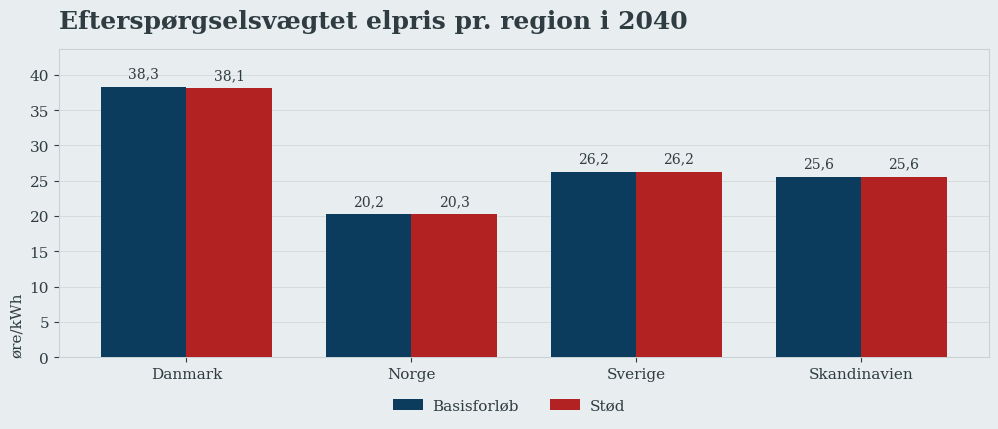

Prisændring, kernekraftforløb − basisforløb — 2040 (øre/kWh)
                Gennemsnitspris  Prisvolatilitet (std.afv.)
───────────────────────────────────────────────────────────
Danmark                   -0,16                       -0,59
Norge                     +0,05                       +0,01
Sverige                   +0,01                       -0,02
Skandinavien              +0,00                       -0,08
───────────────────────────────────────────────────────────



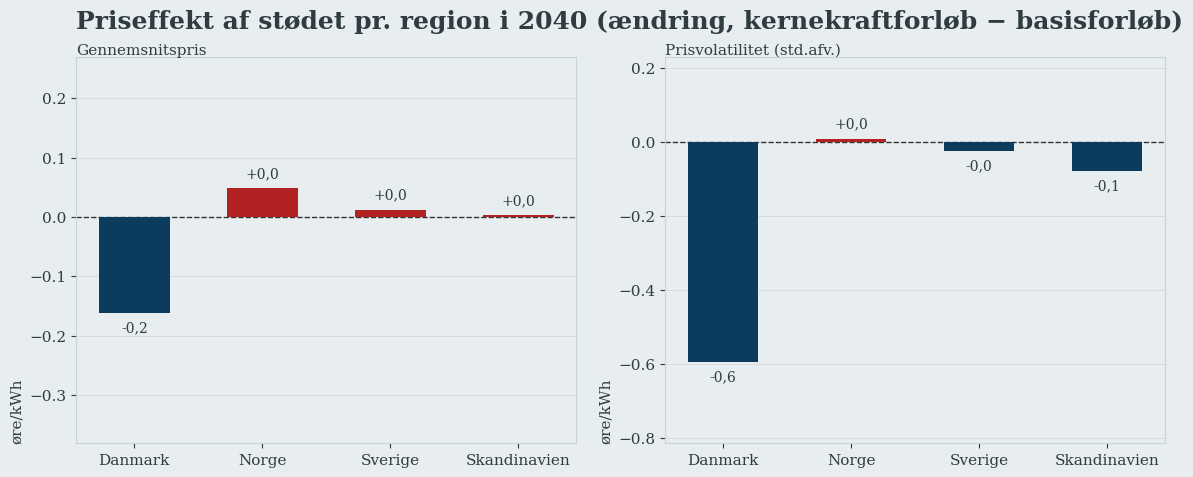

In [7]:
plot_price_levels(ctx_el, years=yr)
plot_price_delta(ctx_el, years=yr, stats=("mean", "std"), verbose=True);

*`5. handel`*

*nettoeksport pr. region i TWh og mia. kr.*

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


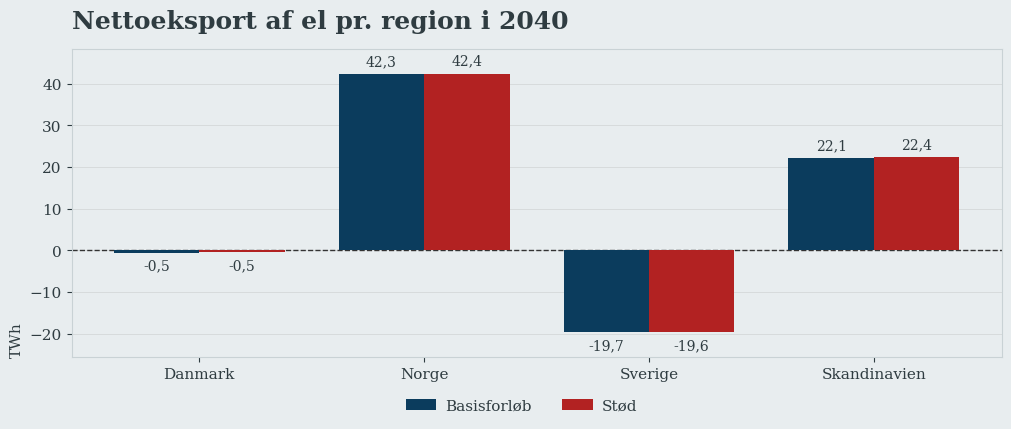

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


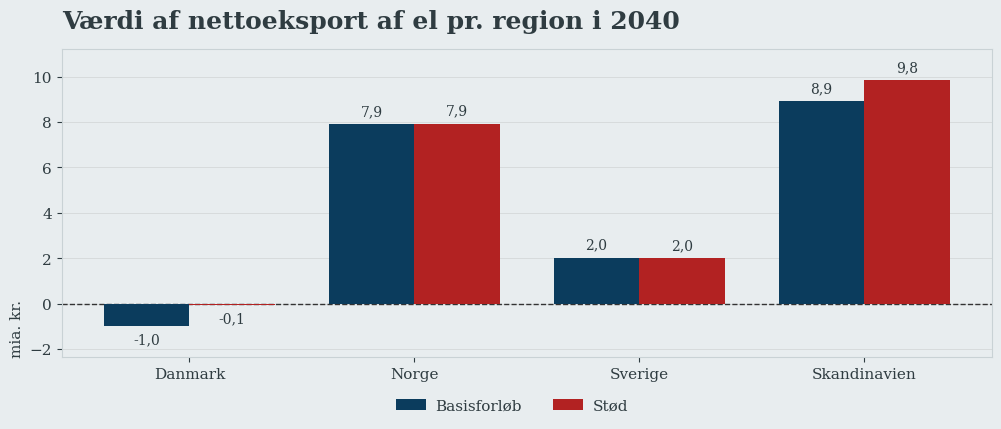

In [8]:
# 5. handel
plot_trade_levels(ctx_el, years=yr)
plot_trade_levels(ctx_el, years=yr, value=True);

*ændring i nettoeksport fordelt på handelspartner*

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


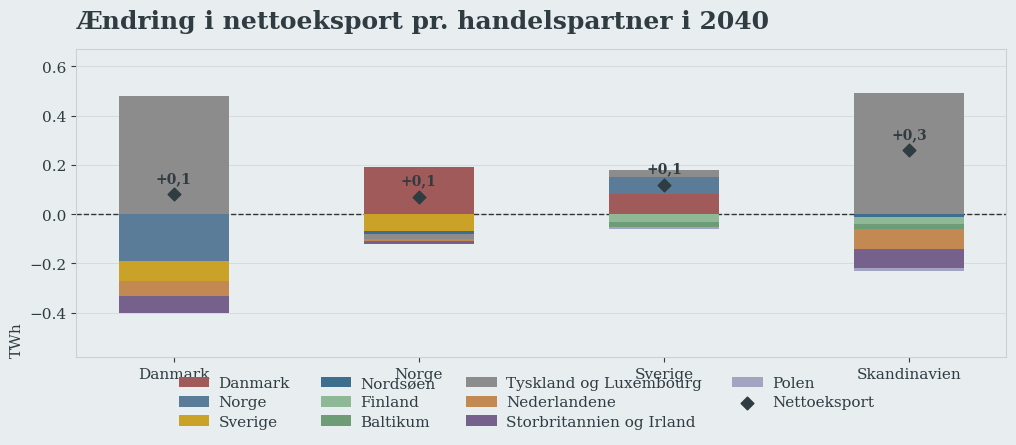

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


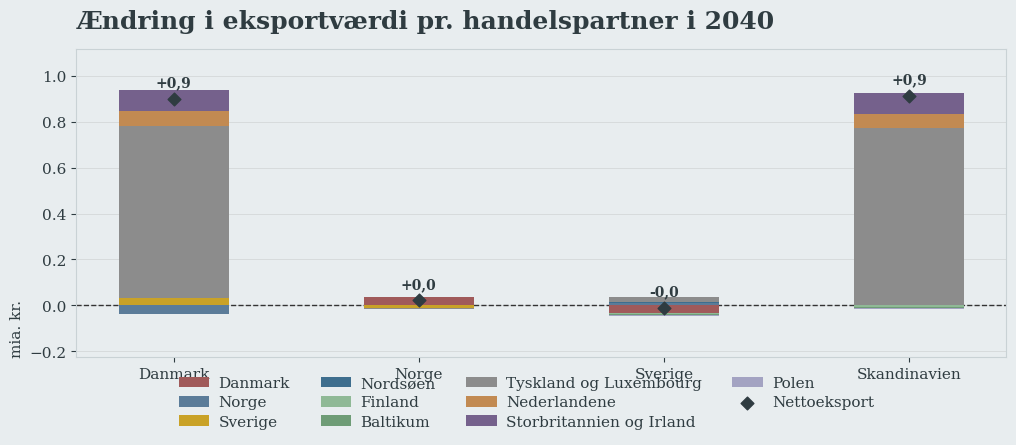

In [9]:
plot_trade_delta_by_partner(ctx_el, years=yr)
plot_trade_delta_by_partner(ctx_el, years=yr, value=True);

*ændring i nettoeksport fordelt på anlægstype og transit*

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


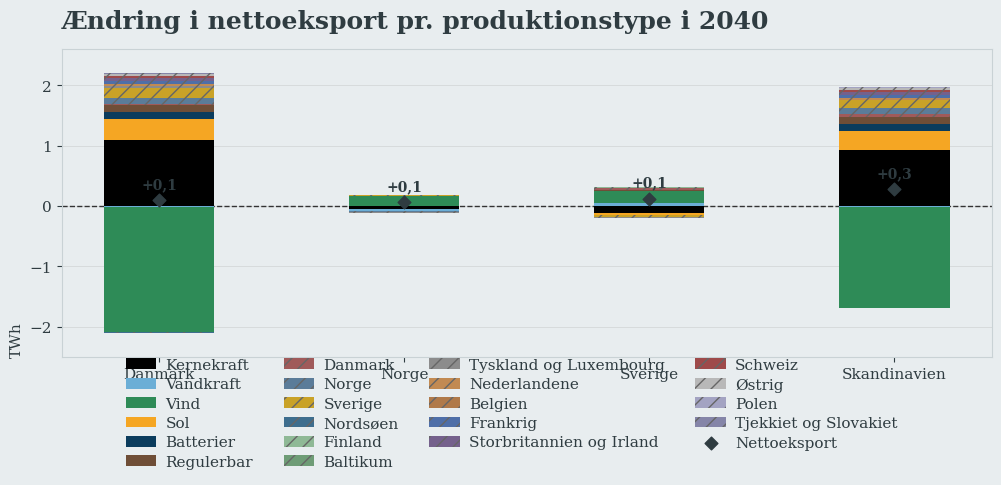

In [10]:
plot_nx_delta_by_pt(ctx_el, shares, years=yr);

*`6. værdifaktor`*

*ændring i fangstpris pr. anlægstype i Danmark*

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


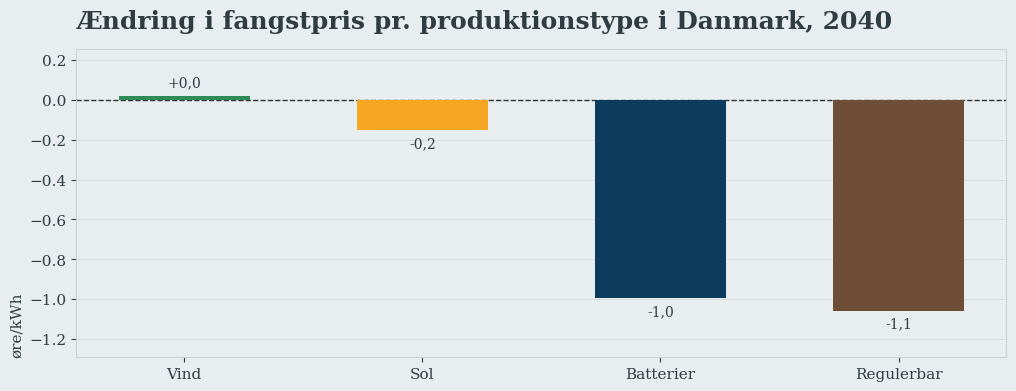

In [11]:
# 6. værdifaktor
plot_capture_delta_by_pt(ctx_el, years=yr);

*`7. velfærd`*

*ΔCS i Danmark fordelt på kvintiler af basisprisen*

Ændring i forbrugeroverskud fordelt på prisniveau, 2040 (mio. kr.)
           0–20 %  20–40 %  40–60 %  60–80 %  80–100 %   I alt
──────────────────────────────────────────────────────────────
Danmark     -30,3    -30,1    -13,6    +23,2    +153,2  +102,5
──────────────────────────────────────────────────────────────



c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


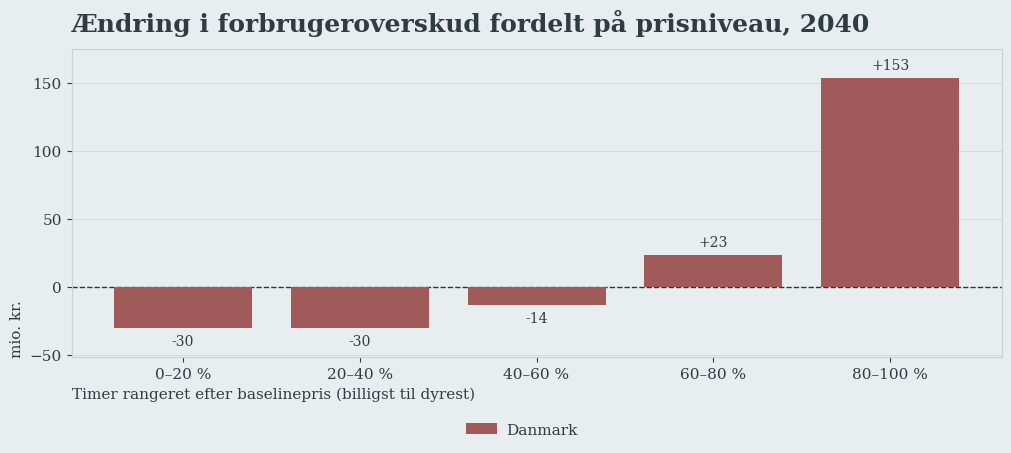

In [12]:
# 7. velfærd
plot_cs_by_price_bin(baseline_output, shock_output, regions=["DK"], year=yr, verbose=True);

*`8. produktion`*

*elproduktion pr. anlægstype og region*

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


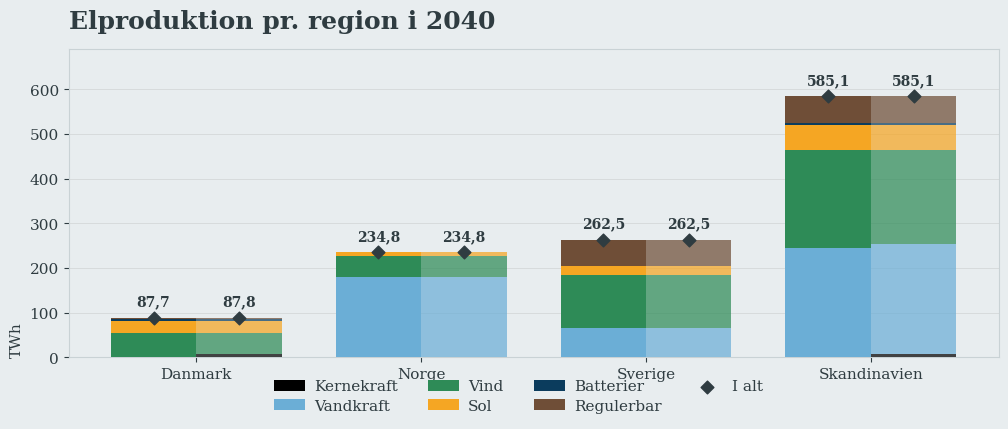

In [13]:
# 8. produktion
plot_generation_stack(baseline_output, shock_output, id2Pt=id2Pt, id2EA=id2EA, year=yr, bar_width=0.38);
# plot_profit_stack(baseline_output, shock_output, id2Pt=id2Pt, id2EA=id2EA, year=yr, bar_width=0.38);

*ændring i produktion og producentoverskud i Danmark*

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


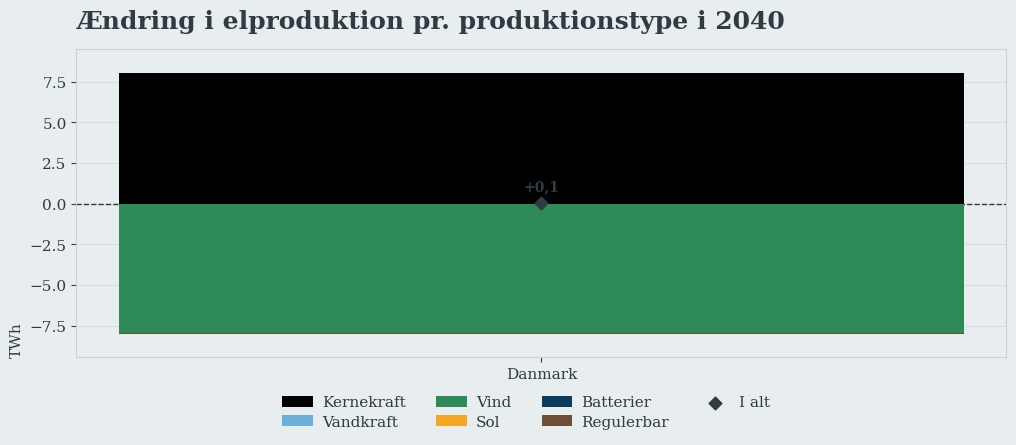

c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)
c:\Users\LinusLindquist\e-tank\E-Tank - Data\PROJEKTER\04 KERNEKRAFT\Grøn Reform beregninger og følgegruppe\GrønREFORM_2.0\KF26_wrapper\ET_pylib\plot_base.py:76: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=list(rect), **kw)


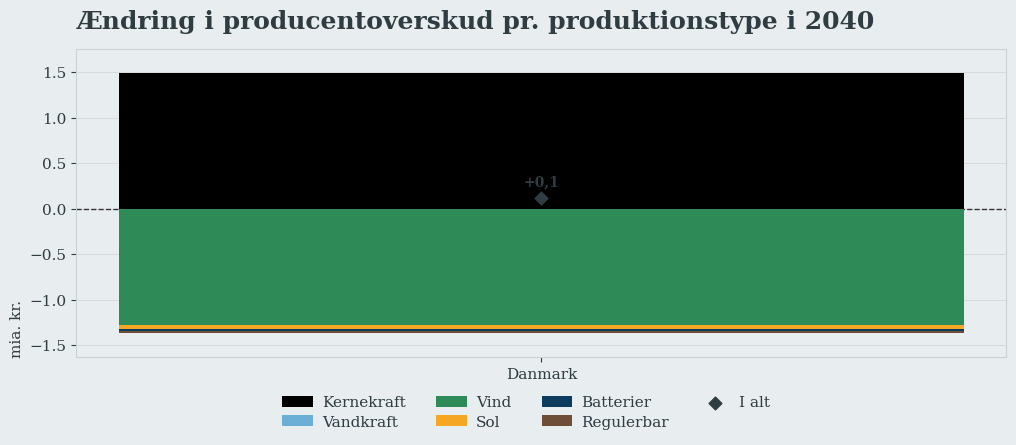

In [14]:
plot_generation_delta(baseline_output, shock_output, id2Pt=id2Pt, id2EA=id2EA, year=yr, regions=["DK"])
plot_profit_delta(baseline_output, shock_output, id2Pt=id2Pt, id2EA=id2EA, year=yr, regions=["DK"]);